# LegibleRx — Predicting low-vision legibility of medicine-strip text regions
**ES 678 project notebook (Colab).** Runs the whole pipeline end to end:

1. Load data — your own annotated pack photos (`DATA_MODE="real"`) **or** a synthetic pack set
   (`DATA_MODE="synthetic"`, the proposal's fallback "render text at varied sizes/contrasts onto foil textures").
2. Proxy label — "OCR survival": each region is degraded on a low-vision ladder (blur + contrast loss + glare veil);
   the score is the number of consecutive levels at which OCR still reads it with CER < τ.
3. Features measured from the clean crop only (prediction-time information): x-height, WCAG contrast,
   specular-glare fraction, curvature, stroke weight, background clutter, box geometry, region type.
4. Product-grouped split (no pack in both train and test), tuning by GroupKFold on the dev set only, one final test.
5. Models: dummy baseline, guideline-rule baseline, LightGBM, (optional) MobileNetV3 crop + features.
6. Metrics: MAE, RMSE, Spearman ρ, R², macro-F1, balanced accuracy, quadratic-weighted κ, illegible recall,
   safety-critical subset, product-clustered bootstrap 95% CIs and paired Δ vs the rule baseline.
7. Depth analyses (ES 678): SHAP, feature-group ablation, τ-sensitivity of the proxy label, conformal prediction
   intervals, failure audit by lighting/region type, worst-error gallery, latency; human-calibration ρ and expert κ
   when those CSVs exist.

Everything is written to `results/` (CSV, JSON, PNG figures ready for the LaTeX paper).

**Runtime:** Runtime → Change runtime type → T4 GPU (needed only for the CNN). Synthetic mode takes ~15–25 min.

In [1]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run("apt-get -qq install -y tesseract-ocr > /dev/null", shell=True)
    subprocess.run(f"{sys.executable} -m pip -q install pytesseract lightgbm shap", shell=True)

In [2]:
DATA_MODE = os.environ.get("DATA_MODE", "synthetic")   # "synthetic" or "real"
QUICK = os.environ.get("QUICK", "0") == "1"            # tiny run for smoke-testing

# --- real-data mode: folder layout -----------------------------------------
# DATA_DIR/images/<image_file>          pack photos
# DATA_DIR/regions.csv                  one row per text region, columns:
#     image_file, product_id, lighting, region_id, x1, y1, x2, y2, text, region_type
#     region_type in {drug_name, strength, dosage, expiry_batch, warning, other}
#     lighting    in {indoor, daylight, bulb_glare}
# DATA_DIR/human_ratings.csv  (optional) region_id, rater_id, rating   (1 = cannot read … 5 = easy)
# DATA_DIR/expert_tags.csv    (optional) region_id, cause  (cause in CAUSES below)
DATA_DIR = "/content/drive/MyDrive/legiblerx_data" if IN_COLAB else "./legiblerx_data"

OUT = "results"
SEED = 42
N_PRODUCTS = 40 if QUICK else 100       # synthetic only
NORM_H = 1000                           # every pack image is resized to this height (pack-relative units)
N_LEVELS = 8                            # low-vision severity ladder: 0 = clean … 8 = severe
TAU = 0.10                              # CER threshold for "OCR still reads it" (proposal: 10 %)
TAU_GRID = [0.05, 0.10, 0.20]           # sensitivity analysis
CLASS_CUTS = (3, 6)                     # score <3 illegible, 3–5 borderline, >=6 legible
CLASS_NAMES = ["illegible", "borderline", "legible"]
SAFETY_TYPES = {"drug_name", "strength", "expiry_batch"}
RUN_CNN = os.environ.get("RUN_CNN", "0" if QUICK else "1") == "1"
N_BOOT = 200 if QUICK else 1000

In [3]:
import json, time, glob, random, re, math, warnings
from multiprocessing import Pool
import numpy as np, pandas as pd, cv2
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import pytesseract
from scipy.stats import spearmanr
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, f1_score,
                             balanced_accuracy_score, cohen_kappa_score, confusion_matrix,
                             classification_report, recall_score)
import lightgbm as lgb
warnings.filterwarnings("ignore")
rng = np.random.default_rng(SEED); random.seed(SEED); np.random.seed(SEED)
os.makedirs(OUT, exist_ok=True); os.makedirs(f"{OUT}/figures", exist_ok=True)
print("mode:", DATA_MODE, "| quick:", QUICK)

mode: synthetic | quick: False


## 1. Data
### 1a. Synthetic pack generator (fallback when real photos are not ready)
Each *product* has a fixed design (font sizes, colours, bold, background, curvature). Each product is
"photographed" under three lightings; `bulb_glare` adds a specular hotspot, strongest on foil.
**If you report results from this mode, say clearly in the paper that they are synthetic.**

In [4]:
FONT_DIRS = ["/usr/share/fonts/truetype/liberation", "/usr/share/fonts/truetype/dejavu"]
def _find_fonts():
    reg, bold = [], []
    for d in FONT_DIRS:
        for f in glob.glob(f"{d}/*.ttf"):
            n = os.path.basename(f)
            if "Mono" in n or "Serif" in n or "Oblique" in n or "Italic" in n or "Math" in n or "Light" in n: continue
            (bold if "Bold" in n else reg).append(f)
    return reg, bold
FONTS_REG, FONTS_BOLD = _find_fonts()

def _font(size, bold):
    pool = FONTS_BOLD if bold else FONTS_REG
    if pool: return ImageFont.truetype(random.choice(pool), size)
    return ImageFont.load_default(size=size)

SYL = ["pa", "ra", "ce", "ta", "mol", "zi", "thro", "my", "cin", "met", "for", "min", "am", "lo", "di", "pine",
       "ator", "va", "sta", "tin", "pan", "to", "pra", "zole", "cef", "ix", "ime", "levo", "flox", "acin"]
def _drugname(): return "".join(random.choice(SYL) for _ in range(random.randint(3, 4))).capitalize()

def _field_texts():
    return {
        "drug_name": _drugname() + random.choice(["", " Tablets", " SR", " 500"]),
        "strength": f"{random.choice([5, 10, 20, 40, 250, 500, 650])} mg",
        "dosage": random.choice(["Take 1 tablet twice daily", "One tablet at bedtime", "Dosage: as directed",
                                 "Take after food", "1 tablet every 8 hours"]),
        "expiry_batch": f"EXP {random.randint(1,12):02d}/{random.randint(2026,2029)} B.No {random.choice('ABCDEFGHK')}"
                        f"{random.choice('XYZTRM')}{random.randint(1000,9999)}",
        "warning": random.choice(["Keep out of reach of children", "Store below 25 C", "Schedule H drug",
                                  "Do not exceed the stated dose", "Protect from light and moisture"]),
        "other": random.choice(["Mfd by Healwell Pharma Ltd", "Each tablet contains", "Mkt by Arogya Labs",
                                "10 x 10 Tablets", "MRP Rs 45.60 incl of all taxes"]),
    }

# font-size ranges in pack-relative px (pack height 1000): drug names large, batch/expiry tiny
SIZE_RANGE = {"drug_name": (34, 80), "strength": (18, 46), "dosage": (11, 30), "expiry_batch": (8, 22),
              "warning": (9, 26), "other": (8, 24)}

def _background(kind, W, H):
    if kind == "foil":
        base = np.linspace(150, 215, W)[None, :].repeat(H, 0)
        base = base + rng.normal(0, 6, (H, W)) + 12 * np.sin(np.arange(H)[:, None] / rng.uniform(15, 40))
        img = np.stack([base, base, base * 1.02], -1)
    elif kind == "white":
        img = np.full((H, W, 3), 240.0) + rng.normal(0, 3, (H, W, 3))
    else:
        c = rng.uniform(80, 230, 3)
        img = np.ones((H, W, 3)) * c + rng.normal(0, 4, (H, W, 3))
    return np.clip(img, 0, 255).astype(np.uint8)

def make_product(pid):
    W, H = 800, NORM_H
    bg_kind = random.choice(["foil", "foil", "white", "colour"])
    texts = _field_texts()
    design = {"pid": pid, "bg": bg_kind, "curv": random.choice([0, 0, rng.uniform(3, 14)]), "fields": []}
    y = 40
    for rtype in ["drug_name", "strength", "dosage", "warning", "other", "expiry_batch"]:
        lo, hi = SIZE_RANGE[rtype]
        size = int(rng.uniform(lo, hi))
        # text colour: mostly dark, sometimes low-contrast print (grey on foil, pastel on colour)
        if random.random() < 0.35:
            col = tuple(int(v) for v in rng.uniform(90, 170, 3))
        else:
            col = tuple(int(v) for v in rng.uniform(0, 60, 3))
        bold = random.random() < (0.7 if rtype == "drug_name" else 0.3)
        x = int(rng.uniform(30, 120))
        while size > 8 and _font(size, bold).getlength(texts[rtype]) > W - x - 30:   # keep text on the pack
            size -= 2
        design["fields"].append({"region_type": rtype, "text": texts[rtype], "size": size, "bold": bold,
                                 "color": col, "x": x, "y": y})
        y += int(size * 1.6 + rng.uniform(40, 110))
        if y > H - 80: break
    return design

def render_photo(design, lighting):
    W, H = 800, NORM_H
    bg = _background(design["bg"], W, H)
    im = Image.fromarray(bg); d = ImageDraw.Draw(im)
    boxes = []
    for f in design["fields"]:
        font = _font(f["size"], f["bold"])
        x, y = f["x"], f["y"]
        d.text((x, y), f["text"], fill=f["color"], font=font)
        x1, y1, x2, y2 = d.textbbox((x, y), f["text"], font=font)
        boxes.append([x1, y1, min(x2, W - 1), y2])
    a = np.asarray(im).astype(np.float32)
    # curvature: sinusoidal vertical displacement (curved strip)
    amp = design["curv"]
    if amp > 0:
        xs = np.arange(W); shift = (amp * np.sin(np.pi * xs / W)).astype(np.float32)
        mapx = np.tile(xs, (H, 1)).astype(np.float32)
        mapy = (np.arange(H)[:, None] - shift[None, :]).astype(np.float32)
        a = cv2.remap(a, mapx, mapy, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
        boxes = [[b[0], b[1], b[2], int(b[3] + amp + 2)] for b in boxes]
    # lighting
    if lighting == "daylight":
        a = a * rng.uniform(1.0, 1.1) + 8
    elif lighting == "indoor":
        a = a * np.array([1.0, 1.0, 0.9]) * rng.uniform(0.85, 0.95)
    else:  # bulb_glare: specular hotspot, stronger on foil
        cx, cy = rng.uniform(0, W), rng.uniform(0, max(f["y"] for f in design["fields"]) + 60)  # hotspot over the print
        r = rng.uniform(80, 220)
        yy, xx = np.mgrid[0:H, 0:W]
        g = np.exp(-((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * r ** 2))
        strength = rng.uniform(150, 260) if design["bg"] == "foil" else rng.uniform(60, 140)
        a = a * 0.9 + strength * g[..., None]
    a = cv2.GaussianBlur(a, (0, 0), rng.uniform(0.3, 0.9))          # camera softness
    a = a + rng.normal(0, 2.5, a.shape)                             # sensor noise
    a = np.clip(a, 0, 255).astype(np.uint8)
    ok, enc = cv2.imencode(".jpg", a[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, int(rng.uniform(70, 92))])
    a = cv2.imdecode(enc, cv2.IMREAD_COLOR)[..., ::-1]
    return a, boxes

def build_synthetic(root, n_products):
    os.makedirs(f"{root}/images", exist_ok=True)
    rows = []
    for p in range(n_products):
        des = make_product(f"P{p:03d}")
        for light in ["indoor", "daylight", "bulb_glare"]:
            img, boxes = render_photo(des, light)
            fn = f"{des['pid']}_{light}.jpg"
            Image.fromarray(img).save(f"{root}/images/{fn}", quality=95)
            for k, (f, b) in enumerate(zip(des["fields"], boxes)):
                rows.append({"image_file": fn, "product_id": des["pid"], "lighting": light,
                             "region_id": f"{des['pid']}_{light}_{k}", "x1": b[0], "y1": b[1], "x2": b[2], "y2": b[3],
                             "text": f["text"], "region_type": f["region_type"],
                             "bg_kind": des["bg"]})
    df = pd.DataFrame(rows); df.to_csv(f"{root}/regions.csv", index=False)
    return df

if DATA_MODE == "synthetic":
    DATA_DIR = "synthetic_data"
    regions = build_synthetic(DATA_DIR, N_PRODUCTS)
else:
    regions = pd.read_csv(f"{DATA_DIR}/regions.csv")
print(regions.shape, regions.product_id.nunique(), "products")
regions.head()

(1800, 11) 100 products


,image_file,product_id,lighting,region_id,x1,y1,x2,y2,text,region_type,bg_kind
0,P000_indoor.jpg,P000,indoor,P000_indoor_0,117,49,610,103,Zolecinmy Tablets,drug_name,foil
1,P000_indoor.jpg,P000,indoor,P000_indoor_1,113,227,228,266,10 mg,strength,foil
2,P000_indoor.jpg,P000,indoor,P000_indoor_2,34,373,350,398,Take 1 tablet twice daily,dosage,foil
3,P000_indoor.jpg,P000,indoor,P000_indoor_3,110,511,373,529,Keep out of reach of children,warning,foil
4,P000_indoor.jpg,P000,indoor,P000_indoor_4,91,633,218,642,Each tablet contains,other,foil


### 1b. Data understanding & quality checks
Row = one annotated text region on one photo. Checks: missing values, invalid/degenerate boxes,
duplicate region ids, empty reference text, per-product photo counts, class/lighting balance.

In [5]:
def load_norm(path):
    im = np.asarray(Image.open(path).convert("RGB"))
    s = NORM_H / im.shape[0]
    return cv2.resize(im, (int(round(im.shape[1] * s)), NORM_H), interpolation=cv2.INTER_AREA), s

qc = {"n_regions": len(regions), "n_images": regions.image_file.nunique(), "n_products": regions.product_id.nunique(),
      "missing_values": int(regions[["x1", "y1", "x2", "y2", "text", "region_type"]].isna().sum().sum()),
      "duplicate_region_ids": int(regions.region_id.duplicated().sum()),
      "degenerate_boxes": int(((regions.x2 - regions.x1) < 4).sum() + ((regions.y2 - regions.y1) < 4).sum()),
      "empty_text": int((regions.text.astype(str).str.strip() == "").sum()),
      "missing_image_files": int(sum(not os.path.exists(f"{DATA_DIR}/images/{f}") for f in regions.image_file.unique()))}
print(json.dumps(qc, indent=1))
print(regions.region_type.value_counts().to_string()); print(regions.lighting.value_counts().to_string())
regions = regions.dropna(subset=["x1", "y1", "x2", "y2", "text"]).drop_duplicates("region_id")
regions = regions[((regions.x2 - regions.x1) >= 4) & ((regions.y2 - regions.y1) >= 4)].reset_index(drop=True)
json.dump(qc, open(f"{OUT}/data_quality.json", "w"), indent=1)

{
 "n_regions": 1800,
 "n_images": 300,
 "n_products": 100,
 "missing_values": 0,
 "duplicate_region_ids": 0,
 "degenerate_boxes": 0,
 "empty_text": 0,
 "missing_image_files": 0
}
region_type
drug_name       300
strength        300
dosage          300
warning         300
other           300
expiry_batch    300
lighting
indoor        600
daylight      600
bulb_glare    600


## 2. Proxy legibility label — OCR survival under simulated low vision
Ladder level s (1…8) applied to the **pack-normalised** crop (so blur is in pack-relative units, like visual angle):
Gaussian blur σ = 0.45·s px, contrast scaled by (1 − 0.08·s) about the mean, veiling glare g = 0.04·s.
We store CER at **every** level so τ can be changed later without re-running OCR.

In [6]:
def degrade(crop, s):
    a = crop.astype(np.float32)
    if s == 0: return crop
    a = cv2.GaussianBlur(a, (0, 0), 0.45 * s)
    m = a.mean(); a = m + (a - m) * (1 - 0.08 * s)
    g = 0.04 * s; a = a * (1 - g) + 255 * g
    return np.clip(a, 0, 255).astype(np.uint8)

def norm_text(t): return re.sub(r"\s+", " ", re.sub(r"[^A-Z0-9/.\s]", "", str(t).upper())).strip()

def cer(hyp, ref):
    h, r = norm_text(hyp), norm_text(ref)
    if not r: return 0.0 if not h else 1.0
    prev = list(range(len(h) + 1))
    for i, rc in enumerate(r, 1):
        cur = [i] + [0] * len(h)
        for j, hc in enumerate(h, 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (rc != hc))
        prev = cur
    return min(prev[-1] / len(r), 1.0)

def ocr(crop):
    up = cv2.resize(crop, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    psm = 7 if crop.shape[1] > 3 * crop.shape[0] else 6
    return pytesseract.image_to_string(up, config=f"--psm {psm}")

_IMG_CACHE = {}
def crop_region(row, pad=4):
    key = row["image_file"]
    if key not in _IMG_CACHE:
        _IMG_CACHE.clear(); _IMG_CACHE[key] = load_norm(f"{DATA_DIR}/images/{key}")
    im, s = _IMG_CACHE[key]
    x1, y1, x2, y2 = [int(round(v * s)) for v in (row["x1"], row["y1"], row["x2"], row["y2"])]
    H, W = im.shape[:2]
    return im[max(0, y1 - pad):min(H, y2 + pad), max(0, x1 - pad):min(W, x2 + pad)]

def ocr_ladder(row):
    crop = crop_region(row)
    return [cer(ocr(degrade(crop, s)), row["text"]) for s in range(N_LEVELS + 1)]

t0 = time.time()
rows = regions.sort_values("image_file").to_dict("records")
with Pool(os.cpu_count()) as pool:
    cers = pool.map(ocr_ladder, rows, chunksize=8)
regions = pd.DataFrame(rows)
cer_mat = np.array(cers)
for s in range(N_LEVELS + 1): regions[f"cer_{s}"] = cer_mat[:, s]
print(f"OCR ladder: {len(rows)} regions x {N_LEVELS+1} levels in {time.time()-t0:.0f}s")

def survival_score(cmat, tau):
    """Number of consecutive degradation levels survived (0 = unreadable even when clean)."""
    ok = cmat < tau
    sc = np.zeros(len(cmat), int)
    for i, r in enumerate(ok):
        if not r[0]: continue
        fails = np.where(~r[1:])[0]
        sc[i] = (fails[0] if len(fails) else N_LEVELS)
    return sc

def to_class(score):
    score = np.asarray(score, float)
    return np.digitize(score, CLASS_CUTS)  # 0 illegible, 1 borderline, 2 legible

regions["score"] = survival_score(cer_mat, TAU)
regions["y_cls"] = to_class(regions.score)
print(regions.score.value_counts().sort_index().to_string())
print(pd.Series(regions.y_cls).map(dict(enumerate(CLASS_NAMES))).value_counts().to_string())

OCR ladder: 1800 regions x 9 levels in 848s
score
0    317
1    122
2    230
3    304
4    256
5    167
6     80
7     63
8    261
y_cls
borderline    727
illegible     669
legible       404


## 3. Features (measured on the clean crop; no label or OCR information used)
All features are deterministic per-region measurements, so there is no learned preprocessing to leak.
The only learned transforms (standardisation for the CNN's feature branch) are fit on the training split only.

In [7]:
def srgb_lum(rgb):
    c = np.asarray(rgb, float) / 255
    c = np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)
    return 0.2126 * c[..., 0] + 0.7152 * c[..., 1] + 0.0722 * c[..., 2]

def region_features(row):
    crop = crop_region(row, pad=2)
    g = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
    _, bw = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    ink = bw == 0 if (bw == 0).mean() < 0.5 else bw == 255          # ink = minority class
    lum = srgb_lum(crop)
    L_ink = np.median(lum[ink]) if ink.any() else lum.mean()
    L_bg = np.median(lum[~ink]) if (~ink).any() else lum.mean()
    contrast = (max(L_ink, L_bg) + 0.05) / (min(L_ink, L_bg) + 0.05)
    n, lab, stats, cent = cv2.connectedComponentsWithStats(ink.astype(np.uint8), 8)
    keep = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= 4]
    hts = np.array([stats[i, cv2.CC_STAT_HEIGHT] for i in keep]) if keep else np.array([g.shape[0] / 2])
    xh = float(np.median(hts))
    if len(keep) >= 4:
        cx = cent[keep, 0]; cy = cent[keep, 1]
        resid = cy - np.polyval(np.polyfit(cx, cy, 1), cx)
        curv = float(np.std(resid) / max(xh, 1))
    else:
        curv = 0.0
    dist = cv2.distanceTransform(ink.astype(np.uint8), cv2.DIST_L2, 3)
    stroke = float(2 * dist[ink].mean() / max(xh, 1)) if ink.any() else 0.0
    hsv = cv2.cvtColor(crop, cv2.COLOR_RGB2HSV)
    glare = float(((hsv[..., 2] > 235) & (hsv[..., 1] < 40)).mean())
    edges = cv2.Canny(g, 60, 160) > 0
    clutter = float(edges[~ink].mean()) if (~ink).any() else 0.0
    h, w = g.shape
    return {"xheight_px": xh, "contrast_ratio": float(contrast), "glare_frac": glare, "curvature": curv,
            "stroke_rel": stroke, "clutter": clutter, "box_h": h, "box_w": w, "aspect": w / max(h, 1),
            "ink_frac": float(ink.mean()), "bg_lum": float(L_bg)}

with Pool(os.cpu_count()) as pool:
    feats = pd.DataFrame(pool.map(region_features, regions.to_dict("records"), chunksize=16))
regions = pd.concat([regions.reset_index(drop=True), feats], axis=1)
for t in ["drug_name", "strength", "dosage", "expiry_batch", "warning", "other"]:
    regions[f"type_{t}"] = (regions.region_type == t).astype(int)

FEATURE_GROUPS = {
    "size": ["xheight_px", "box_h", "box_w", "aspect"],
    "contrast": ["contrast_ratio", "bg_lum", "ink_frac"],
    "glare": ["glare_frac"],
    "curvature": ["curvature"],
    "weight": ["stroke_rel"],
    "clutter": ["clutter"],
    "region_type": [c for c in regions.columns if c.startswith("type_")],
}
FEATS = sum(FEATURE_GROUPS.values(), [])
regions.describe().T.to_csv(f"{OUT}/feature_summary.csv")

# Correlation of each feature with the proxy score (descriptive, all data)
desc = {f: spearmanr(regions[f], regions.score)[0] for f in FEATS if regions[f].std() > 0}
print(pd.Series(desc).sort_values().round(3).to_string())

stroke_rel          -0.729
type_expiry_batch   -0.267
type_other          -0.232
ink_frac            -0.162
type_warning        -0.118
aspect              -0.068
clutter             -0.045
type_dosage          0.019
curvature            0.038
glare_frac           0.045
type_strength        0.144
bg_lum               0.147
box_w                0.415
type_drug_name       0.453
box_h                0.546
contrast_ratio       0.649
xheight_px           0.754


## 4. Evaluation design: product-grouped split
Test = 20 % of **products** (all their photos). Dev = remaining products; within dev a further 15 % of products is
a validation set used only for CNN early stopping and conformal calibration. LightGBM hyper-parameters are
chosen by 5-fold GroupKFold on dev. The test set is scored once per model at the end.

In [8]:
groups = regions.product_id.values
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
dev_idx, test_idx = next(gss.split(regions, groups=groups))
dev, test = regions.iloc[dev_idx].reset_index(drop=True), regions.iloc[test_idx].reset_index(drop=True)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
tr_i, va_i = next(gss2.split(dev, groups=dev.product_id))
train, val = dev.iloc[tr_i].reset_index(drop=True), dev.iloc[va_i].reset_index(drop=True)
assert not set(dev.product_id) & set(test.product_id)
assert not set(train.product_id) & set(val.product_id)
split_info = {k: {"regions": len(d), "products": d.product_id.nunique()} for k, d in
              [("train", train), ("val", val), ("dev", dev), ("test", test)]}
print(split_info); json.dump(split_info, open(f"{OUT}/split.json", "w"), indent=1)
pd.DataFrame({"product_id": sorted(test.product_id.unique())}).to_csv(f"{OUT}/test_products.csv", index=False)

{'train': {'regions': 1224, 'products': 68}, 'val': {'regions': 216, 'products': 12}, 'dev': {'regions': 1440, 'products': 80}, 'test': {'regions': 360, 'products': 20}}


## 5. Models
* **Dummy** — predicts the dev-set mean score / majority class. Floor any model must beat.
* **Rule baseline** — print-guideline thresholds only: x-height ≥ 14 px per 1000 px pack height
  (≈1.4 mm on a 100 mm pack, the common minimum-x-height guidance), WCAG contrast ≥ 4.5:1, glare ≤ 5 %.
  0 violations → legible, 1 → borderline, ≥2 → illegible; score = dev median score for that violation count.
* **LightGBM** — regression on the hand-measured features, tuned by GroupKFold; the two class cut-offs on its
  predicted score are chosen to maximise macro-F1 on dev out-of-fold predictions (never on test).
* **CNN** — MobileNetV3-Small on the crop + an MLP on the features (late fusion), regression head.

In [9]:
def metrics(y, yhat, y_cls=None, cls_hat=None):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    y_cls = to_class(y) if y_cls is None else y_cls
    cls_hat = to_class(yhat) if cls_hat is None else cls_hat
    rho = spearmanr(y, yhat)[0] if np.ptp(yhat) > 0 else 0.0
    return {"MAE": mean_absolute_error(y, yhat), "RMSE": mean_squared_error(y, yhat) ** 0.5,
            "R2": r2_score(y, yhat), "Spearman": rho,
            "macro_F1": f1_score(y_cls, cls_hat, average="macro", labels=[0, 1, 2], zero_division=0),
            "bal_acc": balanced_accuracy_score(y_cls, cls_hat),
            "QWK": cohen_kappa_score(y_cls, cls_hat, weights="quadratic", labels=[0, 1, 2]),
            "illegible_recall": recall_score(y_cls, cls_hat, labels=[0], average="macro", zero_division=0)}

def cluster_bootstrap(df, pred_cols, fn, n=N_BOOT, seed=SEED):
    """Resample products with replacement; returns {col: array of metric values}."""
    r = np.random.default_rng(seed); prods = df.product_id.unique()
    by = {p: np.where(df.product_id.values == p)[0] for p in prods}
    out = {c: [] for c in pred_cols}
    for _ in range(n):
        idx = np.concatenate([by[p] for p in r.choice(prods, len(prods), replace=True)])
        for c in pred_cols: out[c].append(fn(df.iloc[idx], c))
    return {c: np.array(v) for c, v in out.items()}

def ci(a): return [float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))]

In [10]:
preds = test[["region_id", "product_id", "lighting", "region_type", "score", "y_cls"]].copy()
preds["dummy"] = dev.score.mean()
preds["dummy_cls"] = int(pd.Series(dev.y_cls).mode()[0])

def rule_violations(d):
    return ((d.xheight_px < 14).astype(int) + (d.contrast_ratio < 4.5).astype(int) + (d.glare_frac > 0.05).astype(int))
v_dev = rule_violations(dev)
v2score = dev.groupby(v_dev).score.median().to_dict()
v_test = rule_violations(test)
preds["rule"] = v_test.map(lambda v: v2score.get(v, dev.score.median()))
preds["rule_cls"] = np.select([v_test == 0, v_test == 1], [2, 1], 0)

In [11]:
gkf = GroupKFold(n_splits=5)
grid = [{"num_leaves": nl, "min_child_samples": mc, "learning_rate": lr, "n_estimators": ne}
        for nl in [7, 15, 31] for mc in [10, 30] for lr in [0.03, 0.1] for ne in [200, 500]]
if QUICK: grid = grid[:4]
def lgb_model(p, feats=None, **kw):
    return lgb.LGBMRegressor(**p, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                             random_state=SEED, verbose=-1, **kw)
def cv_oof(p, feats, target="score", data=None):
    data = dev if data is None else data
    oof = np.zeros(len(data))
    for tr, va in gkf.split(data, groups=data.product_id):
        m = lgb_model(p).fit(data.iloc[tr][feats], data.iloc[tr][target])
        oof[va] = m.predict(data.iloc[va][feats])
    return oof
cv_rows = []
for p in grid:
    oof = cv_oof(p, FEATS)
    cv_rows.append({**p, "cv_MAE": mean_absolute_error(dev.score, oof),
                    "cv_macro_F1": f1_score(dev.y_cls, to_class(oof), average="macro")})
cv_df = pd.DataFrame(cv_rows).sort_values("cv_MAE"); cv_df.to_csv(f"{OUT}/lgb_cv_grid.csv", index=False)
BEST = {k: (int(v) if k != "learning_rate" else float(v)) for k, v in cv_df.iloc[0][list(grid[0])].items()}
print("best params:", BEST, "| CV MAE", round(cv_df.iloc[0].cv_MAE, 3))
oof_best = cv_oof(BEST, FEATS)

def tune_cuts(y_cls, yhat):
    """Pick the two score cut-offs that maximise macro-F1 on held-out (OOF / val) predictions — never on test."""
    best_c, best_f = CLASS_CUTS, -1
    for c1 in np.arange(1.0, 5.01, 0.25):
        for c2 in np.arange(c1 + 0.5, 7.51, 0.25):
            f = f1_score(y_cls, np.digitize(yhat, (c1, c2)), average="macro", labels=[0, 1, 2], zero_division=0)
            if f > best_f: best_c, best_f = (float(c1), float(c2)), f
    return best_c
LGB_CUTS = tune_cuts(dev.y_cls, oof_best)
print("LightGBM class cut-offs tuned on dev OOF:", LGB_CUTS)
lgbm = lgb_model(BEST).fit(dev[FEATS], dev.score)
preds["lgbm"] = np.clip(lgbm.predict(test[FEATS]), 0, N_LEVELS)
preds["lgbm_cls"] = np.digitize(preds.lgbm, LGB_CUTS)

best params: {'num_leaves': 31, 'min_child_samples': 10, 'learning_rate': 0.03, 'n_estimators': 200} | CV MAE 0.777


LightGBM class cut-offs tuned on dev OOF: (2.25, 5.25)


In [12]:
if RUN_CNN:
    import torch, torch.nn as nn, torchvision
    dev_t = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(SEED)
    CH, CW = 64, 256
    mu, sd = train[FEATS].mean(), train[FEATS].std().replace(0, 1)       # fit on TRAIN only
    def to_tensor(d):
        X = np.stack([cv2.resize(crop_region(r), (CW, CH), interpolation=cv2.INTER_AREA)
                      for r in d.to_dict("records")]).astype(np.float32) / 255
        X = (X - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
        F = ((d[FEATS] - mu) / sd).values.astype(np.float32)
        return (torch.tensor(X, dtype=torch.float32).permute(0, 3, 1, 2), torch.tensor(F),
                torch.tensor(d.score.values, dtype=torch.float32))
    data_tr, data_va, data_te = to_tensor(train), to_tensor(val), to_tensor(test)
    class Net(nn.Module):
        def __init__(s):
            super().__init__()
            try: w = torchvision.models.MobileNet_V3_Small_Weights.IMAGENET1K_V1; bb = torchvision.models.mobilenet_v3_small(weights=w)
            except Exception as e: print("ImageNet weights unavailable, random init:", e); bb = torchvision.models.mobilenet_v3_small()
            s.cnn = nn.Sequential(bb.features, nn.AdaptiveAvgPool2d(1), nn.Flatten())
            s.fm = nn.Sequential(nn.Linear(len(FEATS), 64), nn.ReLU())
            s.head = nn.Sequential(nn.Linear(576 + 64, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 1))
        def forward(s, x, f): return s.head(torch.cat([s.cnn(x), s.fm(f)], 1)).squeeze(1)
    net = Net().to(dev_t)
    opt = torch.optim.AdamW(net.parameters(), lr=3e-4, weight_decay=1e-4)
    def run(data, train_mode, bs=64):
        X, F, y = data; idx = torch.randperm(len(y)) if train_mode else torch.arange(len(y))
        net.train(train_mode); out = []; tot = 0
        for i in range(0, len(y), bs):
            b = idx[i:i + bs]; xb, fb, yb = X[b].to(dev_t), F[b].to(dev_t), y[b].to(dev_t)
            if train_mode and random.random() < 0.5: xb = xb + 0.05 * torch.randn_like(xb)   # light augmentation
            with torch.set_grad_enabled(train_mode):
                p = net(xb, fb); loss = nn.functional.smooth_l1_loss(p, yb)
                if train_mode: opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(b); out.append(p.detach().cpu())
        return tot / len(y), torch.cat(out).numpy()
    best_va, best_state, patience, hist = 1e9, None, 0, []
    for ep in range(25):
        tl, _ = run(data_tr, True); vl, vp = run(data_va, False)
        vmae = mean_absolute_error(val.score, vp); hist.append((ep, tl, vmae))
        if vmae < best_va - 1e-3: best_va, best_state, patience = vmae, {k: v.clone() for k, v in net.state_dict().items()}, 0
        else: patience += 1
        if patience >= 6: break
    net.load_state_dict(best_state)
    print(f"CNN stopped at epoch {ep}, best val MAE {best_va:.3f}")
    pd.DataFrame(hist, columns=["epoch", "train_loss", "val_MAE"]).to_csv(f"{OUT}/cnn_history.csv", index=False)
    _, vp = run(data_va, False); CNN_CUTS = tune_cuts(val.y_cls, vp)
    _, tp = run(data_te, False)
    preds["cnn"] = np.clip(tp, 0, N_LEVELS); preds["cnn_cls"] = np.digitize(preds.cnn, CNN_CUTS)

MODELS = ["dummy", "rule", "lgbm"] + (["cnn"] if RUN_CNN else [])

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


ImageNet weights unavailable, random init: <urlopen error Tunnel connection failed: 403 Forbidden>


CNN stopped at epoch 24, best val MAE 1.543


## 6. Test-set results with product-clustered bootstrap CIs

            MAE      RMSE        R2  Spearman  macro_F1   bal_acc       QWK illegible_recall                               macro_F1_CI95                                  MAE_CI95 dF1_vs_rule                             dF1_vs_rule_CI95
dummy  2.111285  2.553206 -0.004534       0.0  0.193294  0.333333       0.0              0.0  [0.16352201257861634, 0.21806853582554517]    [1.924115451388889, 2.321154513888889]   -0.397713  [-0.4770644272918487, -0.32453161424388643]
rule   1.630556  2.180087  0.267613  0.640098  0.591289  0.595129  0.596275         0.857143    [0.5302266851784078, 0.6562134274301201]  [1.4444444444444444, 1.8195138888888889]         0.0                                   [0.0, 0.0]
lgbm   0.812222  1.286296  0.745039  0.849893    0.8047  0.804389  0.772456              0.7    [0.7516807052793284, 0.8561251198840983]  [0.7076858572253654, 0.9160944002739153]     0.21398   [0.14407293296437232, 0.28110278937007893]
cnn    1.625374  1.877445   0.45684  0.676342  0.689354 

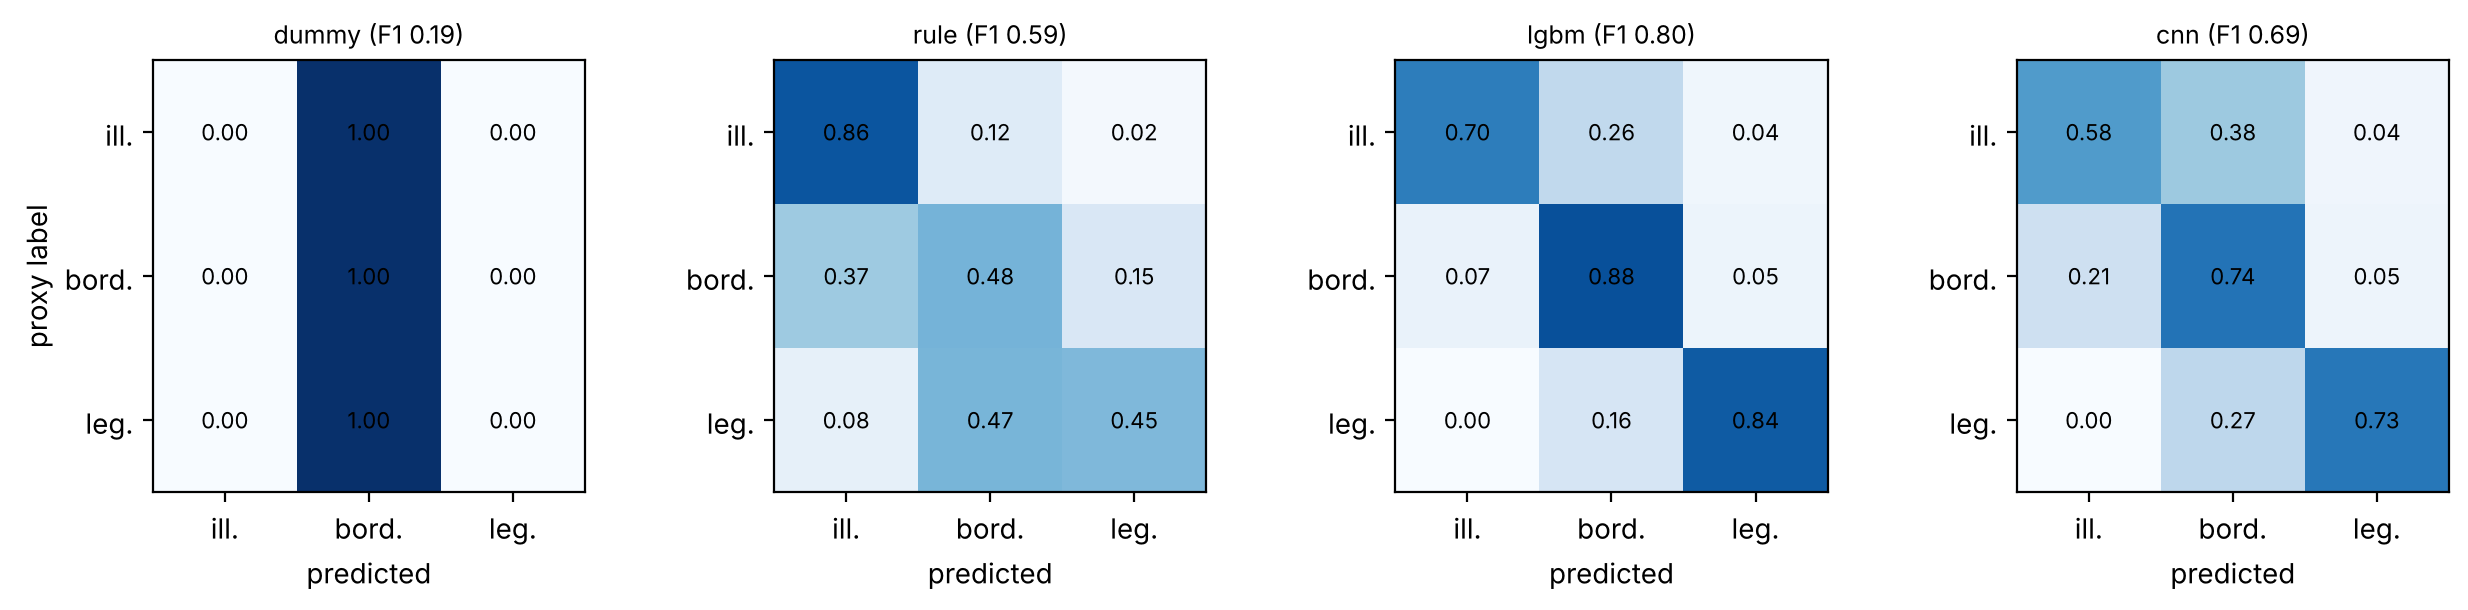

In [13]:
res, res_safety = {}, {}
safety = preds.region_type.isin(SAFETY_TYPES).values
for m in MODELS:
    res[m] = metrics(preds.score, preds[m], preds.y_cls, preds[f"{m}_cls"])
    res_safety[m] = metrics(preds.score[safety], preds[m][safety], preds.y_cls[safety], preds[f"{m}_cls"][safety])
f1_of = lambda d, m: f1_score(d.y_cls, d[f"{m}_cls"], average="macro", labels=[0, 1, 2], zero_division=0)
mae_of = lambda d, m: mean_absolute_error(d.score, d[m])
b_f1 = cluster_bootstrap(preds, MODELS, f1_of); b_mae = cluster_bootstrap(preds, MODELS, mae_of)
for m in MODELS:
    res[m]["macro_F1_CI95"] = ci(b_f1[m]); res[m]["MAE_CI95"] = ci(b_mae[m])
    d = b_f1[m] - b_f1["rule"]; res[m]["dF1_vs_rule"] = float(np.mean(d)); res[m]["dF1_vs_rule_CI95"] = ci(d)
table = pd.DataFrame(res).T; table_s = pd.DataFrame(res_safety).T
print(table.round(3).to_string()); print("\nSafety-critical regions:\n", table_s.round(3).to_string())
table.to_csv(f"{OUT}/test_metrics.csv"); table_s.to_csv(f"{OUT}/test_metrics_safety.csv")
preds.to_csv(f"{OUT}/test_predictions.csv", index=False)
best = max([m for m in MODELS if m not in ("dummy", "rule")], key=lambda m: res[m]["macro_F1"])
print("\nBest model:", best)
print(classification_report(preds.y_cls, preds[f"{best}_cls"], labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0))

fig, axes = plt.subplots(1, len(MODELS), figsize=(3.2 * len(MODELS), 3))
for ax, m in zip(axes, MODELS):
    cm = confusion_matrix(preds.y_cls, preds[f"{m}_cls"], labels=[0, 1, 2], normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3): ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(3), ["ill.", "bord.", "leg."]); ax.set_yticks(range(3), ["ill.", "bord.", "leg."])
    ax.set_title(f"{m} (F1 {res[m]['macro_F1']:.2f})", fontsize=9); ax.set_xlabel("predicted")
axes[0].set_ylabel("proxy label"); plt.tight_layout(); plt.savefig(f"{OUT}/figures/confusion.png", dpi=200); plt.show()

## 7. Depth analyses (ES 678)
### 7a. SHAP — which factors drive predicted legibility (RQ2)

size           0.988
weight         0.686
contrast       0.619
region_type    0.179
curvature      0.132
glare          0.066
clutter        0.056


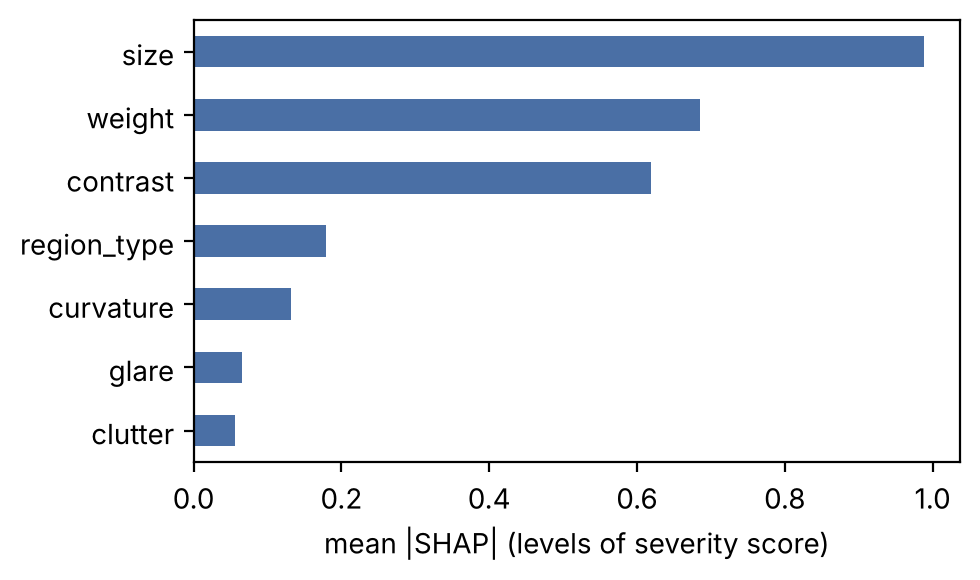

In [14]:
import shap
expl = shap.TreeExplainer(lgbm)
sv = expl.shap_values(test[FEATS])
imp = pd.Series(np.abs(sv).mean(0), index=FEATS).sort_values(ascending=False)
grp_imp = pd.Series({g: np.abs(sv[:, [FEATS.index(f) for f in fs]].sum(1)).mean()
                     for g, fs in FEATURE_GROUPS.items()}).sort_values(ascending=False)
imp.to_csv(f"{OUT}/shap_feature.csv"); grp_imp.to_csv(f"{OUT}/shap_group.csv")
print(grp_imp.round(3).to_string())
plt.figure(figsize=(5, 3)); grp_imp[::-1].plot.barh(color="#4a6fa5")
plt.xlabel("mean |SHAP| (levels of severity score)"); plt.tight_layout()
plt.savefig(f"{OUT}/figures/shap_groups.png", dpi=200); plt.show()

### 7b. Feature-group ablation (GroupKFold on dev — the test set is not reused)

In [15]:
abl = [{"dropped": "none", "cv_MAE": mean_absolute_error(dev.score, oof_best),
        "cv_macro_F1": f1_score(dev.y_cls, np.digitize(oof_best, LGB_CUTS), average="macro")}]
for g, fs in FEATURE_GROUPS.items():
    keep = [f for f in FEATS if f not in fs]
    o = cv_oof(BEST, keep)
    abl.append({"dropped": g, "cv_MAE": mean_absolute_error(dev.score, o),
                "cv_macro_F1": f1_score(dev.y_cls, np.digitize(o, LGB_CUTS), average="macro")})
abl = pd.DataFrame(abl)
abl["dMAE"] = abl.cv_MAE - abl.cv_MAE[0]; abl["dF1"] = abl.cv_macro_F1 - abl.cv_macro_F1[0]
abl.to_csv(f"{OUT}/ablation.csv", index=False); print(abl.round(3).to_string())

       dropped  cv_MAE  cv_macro_F1   dMAE    dF1
0         none   0.777        0.816  0.000  0.000
1         size   0.809        0.802  0.032 -0.013
2     contrast   0.837        0.808  0.060 -0.007
3        glare   0.781        0.820  0.004  0.004
4    curvature   0.785        0.810  0.008 -0.006
5       weight   0.808        0.809  0.031 -0.007
6      clutter   0.765        0.818 -0.012  0.002
7  region_type   0.809        0.815  0.032 -0.000


### 7c. Sensitivity of the proxy label to the CER threshold τ
How much do labels change, and do conclusions survive? (Re-uses stored CERs; fixed hyper-parameters.)

In [16]:
sens = []
for tau in TAU_GRID:
    s_all = survival_score(regions[[f"cer_{s}" for s in range(N_LEVELS + 1)]].values, tau)
    rs = regions.assign(score=s_all, y_cls=to_class(s_all))
    d_, t_ = rs.iloc[dev_idx], rs.iloc[test_idx]
    m = lgb_model(BEST).fit(d_[FEATS], d_.score); p = np.clip(m.predict(t_[FEATS]), 0, N_LEVELS)
    r = metrics(t_.score, p)
    sens.append({"tau": tau, "rho_label_vs_tau0.10": spearmanr(s_all, regions.score)[0],
                 "pct_illegible": float((to_class(s_all) == 0).mean()), "mean_score": float(s_all.mean()),
                 "test_MAE": r["MAE"], "test_macro_F1": r["macro_F1"], "test_Spearman": r["Spearman"]})
sens = pd.DataFrame(sens); sens.to_csv(f"{OUT}/tau_sensitivity.csv", index=False); print(sens.round(3).to_string())

    tau  rho_label_vs_tau0.10  pct_illegible  mean_score  test_MAE  test_macro_F1  test_Spearman
0  0.05                 0.961          0.425       3.263     0.919          0.749          0.830
1  0.10                 1.000          0.372       3.534     0.812          0.774          0.850
2  0.20                 0.967          0.325       3.814     0.769          0.757          0.871


### 7d. Uncertainty — split-conformal 90 % prediction intervals
Non-conformity scores = |out-of-fold residual| on dev (GroupKFold), so calibration never touches the test set.

In [17]:
alpha = 0.10
q = np.quantile(np.abs(dev.score - oof_best), np.ceil((len(dev) + 1) * (1 - alpha)) / len(dev))
lo, hi = preds.lgbm - q, preds.lgbm + q
preds["covered"] = (preds.score >= lo) & (preds.score <= hi)
conf = {"alpha": alpha, "half_width_levels": float(q), "coverage_test": float(preds.covered.mean()),
        "coverage_by_lighting": preds.groupby("lighting").covered.mean().round(3).to_dict(),
        "coverage_by_type": preds.groupby("region_type").covered.mean().round(3).to_dict()}
print(json.dumps(conf, indent=1)); json.dump(conf, open(f"{OUT}/conformal.json", "w"), indent=1)

{
 "alpha": 0.1,
 "half_width_levels": 1.8319169216567466,
 "coverage_test": 0.8611111111111112,
 "coverage_by_lighting": {
  "bulb_glare": 0.858,
  "daylight": 0.858,
  "indoor": 0.867
 },
 "coverage_by_type": {
  "dosage": 0.95,
  "drug_name": 0.75,
  "expiry_batch": 0.983,
  "other": 0.983,
  "strength": 0.617,
  "warning": 0.883
 }
}


### 7e. Failure audit — errors by lighting and region type, and the worst errors

                n    MAE  macro_F1  MAE_rule
lighting                                    
bulb_glare  120.0  0.786     0.872     1.717
daylight    120.0  0.879     0.739     1.567
indoor      120.0  0.772     0.804     1.608
                 n    MAE  illegible_recall  pct_illegible
region_type                                               
dosage        60.0  0.662             0.812          0.267
drug_name     60.0  1.102             0.200          0.167
expiry_batch  60.0  0.337             0.900          0.667
other         60.0  0.557             0.733          0.500
strength      60.0  1.466             0.333          0.300
warning       60.0  0.748             0.731          0.433


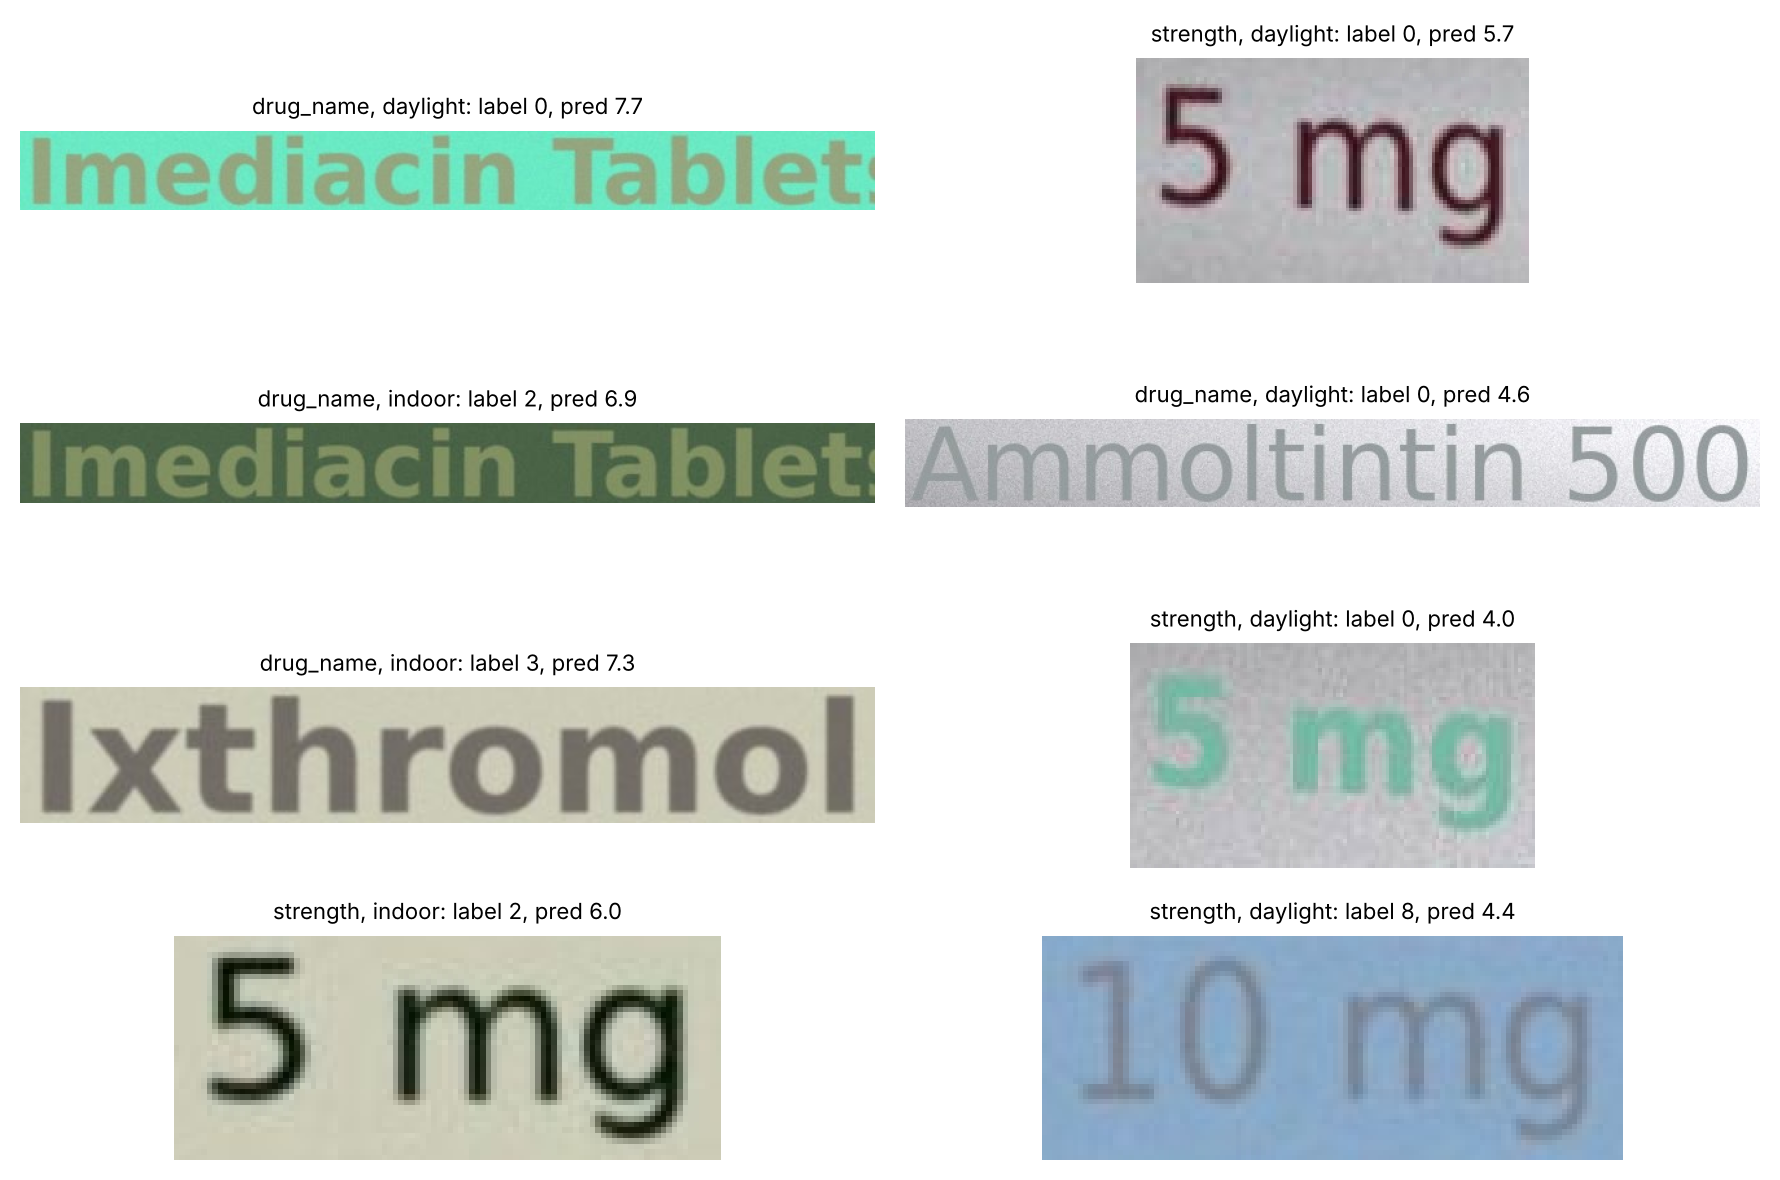

In [18]:
preds["abs_err"] = (preds[best] - preds.score).abs()
by_light = preds.groupby("lighting").apply(lambda d: pd.Series(
    {"n": len(d), "MAE": d.abs_err.mean(), "macro_F1": f1_score(d.y_cls, d[f"{best}_cls"], average="macro", labels=[0,1,2], zero_division=0),
     "MAE_rule": (d.rule - d.score).abs().mean()}))
by_type = preds.groupby("region_type").apply(lambda d: pd.Series(
    {"n": len(d), "MAE": d.abs_err.mean(), "illegible_recall":
     recall_score(d.y_cls, d[f"{best}_cls"], labels=[0], average="macro", zero_division=0), "pct_illegible": (d.y_cls == 0).mean()}))
by_light.to_csv(f"{OUT}/errors_by_lighting.csv"); by_type.to_csv(f"{OUT}/errors_by_type.csv")
print(by_light.round(3).to_string()); print(by_type.round(3).to_string())

worst = preds.sort_values("abs_err", ascending=False).head(8)
lookup = test.set_index("region_id")
fig, axes = plt.subplots(4, 2, figsize=(9, 6))
for ax, (_, r) in zip(axes.ravel(), worst.iterrows()):
    ax.imshow(crop_region(lookup.loc[r.region_id].to_dict()))
    ax.set_title(f"{r.region_type}, {r.lighting}: label {r.score}, pred {r[best]:.1f}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/worst_errors.png", dpi=200); plt.show()
worst.merge(test[["region_id"] + FEATS], on="region_id").to_csv(f"{OUT}/worst_errors.csv", index=False)

### 7f. Actionable explanations (RQ3)
For each region predicted not-legible, the cause is the guideline-linked feature group with the most negative SHAP.

In [19]:
CAUSES = {"size": "text too small (x-height < 1.4 mm equivalent)", "contrast": "low contrast (needs >= 4.5:1)",
          "glare": "foil/specular glare", "curvature": "curved or warped surface", "weight": "stroke too thin",
          "clutter": "busy background"}
grp_sv = pd.DataFrame({g: sv[:, [FEATS.index(f) for f in fs]].sum(1) for g, fs in FEATURE_GROUPS.items() if g in CAUSES})
test_expl = preds[["region_id", "region_type", "lighting", "score", "lgbm", "lgbm_cls"]].copy()
test_expl["cause"] = grp_sv.idxmin(axis=1).values
test_expl["cause_text"] = test_expl.cause.map(CAUSES)
test_expl.loc[test_expl.lgbm_cls == 2, ["cause", "cause_text"]] = ["none", "legible"]
test_expl.to_csv(f"{OUT}/test_explanations.csv", index=False)
print(test_expl[test_expl.cause != "none"].cause.value_counts().to_string())

cause
size         148
contrast      73
weight        44
curvature      8
clutter        7
glare          6


### 7g. Human calibration (RQ1) and expert agreement (RQ3) — only if the CSVs exist
These sets must be held out from training: the regions are matched against the predictions of the final model.

In [20]:
val_out = {}
hp = f"{DATA_DIR}/human_ratings.csv"
if os.path.exists(hp):
    hr = pd.read_csv(hp)
    piv = hr.pivot_table(index="region_id", columns="rater_id", values="rating")
    rr = [spearmanr(piv[a], piv[b], nan_policy="omit")[0] for i, a in enumerate(piv) for b in list(piv)[i + 1:]]
    hm = hr.groupby("region_id").rating.mean().rename("human")
    allp = regions.set_index("region_id")
    allp["lgbm_pred"] = np.clip(lgbm.predict(allp[FEATS]), 0, N_LEVELS)
    j = allp.join(hm, how="inner")
    leaked = len(set(j.index) & set(dev.region_id))
    rho_m, rho_p = spearmanr(j.human, j.lgbm_pred)[0], spearmanr(j.human, j.score)[0]
    bs = [spearmanr(*j.sample(len(j), replace=True, random_state=i)[["human", "lgbm_pred"]].values.T)[0] for i in range(N_BOOT)]
    val_out["human"] = {"n_regions": len(j), "n_raters": piv.shape[1], "mean_pairwise_rater_rho": float(np.nanmean(rr)),
                        "rho_model_vs_human": rho_m, "rho_model_CI95": ci(bs), "rho_proxy_vs_human": rho_p,
                        "WARNING_regions_also_in_training": leaked}
else:
    print("No human_ratings.csv — RQ1 human validation skipped (do not report it).")
ep = f"{DATA_DIR}/expert_tags.csv"
if os.path.exists(ep):
    et = pd.read_csv(ep).rename(columns={"cause": "expert"}).merge(
        test_expl[["region_id", "cause"]].rename(columns={"cause": "model"}), on="region_id")
    val_out["expert"] = {"n": len(et), "cohen_kappa": cohen_kappa_score(et.expert, et.model),
                         "raw_agreement": float((et.expert == et.model).mean())}
else:
    print("No expert_tags.csv — RQ3 expert agreement skipped.")
json.dump(val_out, open(f"{OUT}/human_expert_validation.json", "w"), indent=1, default=float); print(val_out)

No human_ratings.csv — RQ1 human validation skipped (do not report it).
No expert_tags.csv — RQ3 expert agreement skipped.
{}


### 7h. Latency — features + LightGBM per image (OCR detection excluded; boxes given)

In [21]:
imgs = test.image_file.unique()[:20]; ts = []
for f in imgs:
    _IMG_CACHE.clear(); t0 = time.perf_counter()
    rs = test[test.image_file == f]
    F = pd.DataFrame([region_features(r) for r in rs.to_dict("records")])
    for t in ["drug_name", "strength", "dosage", "expiry_batch", "warning", "other"]: F[f"type_{t}"] = (rs.region_type.values == t).astype(int)
    lgbm.predict(F[FEATS]); ts.append(time.perf_counter() - t0)
lat = {"median_s_per_image": float(np.median(ts)), "p95_s_per_image": float(np.percentile(ts, 95))}
print(lat); json.dump(lat, open(f"{OUT}/latency.json", "w"))

{'median_s_per_image': 0.01715779100004511, 'p95_s_per_image': 0.02196914140004084}


## 8. Summary for the paper + download

In [22]:
summary = {"data_mode": DATA_MODE, "quality": qc, "split": split_info, "tau": TAU, "class_cuts": CLASS_CUTS,
           "label_distribution": pd.Series(regions.y_cls).map(dict(enumerate(CLASS_NAMES))).value_counts().to_dict(),
           "lgbm_params": BEST, "test": table.to_dict(orient="index"), "test_safety": table_s.to_dict(orient="index"),
           "shap_groups": grp_imp.to_dict(), "conformal": conf, "latency": lat, "human_expert": val_out}
json.dump(summary, open(f"{OUT}/summary.json", "w"), indent=1, default=float)
print(table[["MAE", "Spearman", "macro_F1", "macro_F1_CI95", "dF1_vs_rule", "dF1_vs_rule_CI95", "QWK", "illegible_recall"]].round(3).to_string())
if IN_COLAB:
    subprocess.run(f"zip -qr results.zip {OUT}", shell=True)
    from google.colab import files; files.download("results.zip")

            MAE  Spearman  macro_F1                               macro_F1_CI95 dF1_vs_rule                             dF1_vs_rule_CI95       QWK illegible_recall
dummy  2.111285       0.0  0.193294  [0.16352201257861634, 0.21806853582554517]   -0.397713  [-0.4770644272918487, -0.32453161424388643]       0.0              0.0
rule   1.630556  0.640098  0.591289    [0.5302266851784078, 0.6562134274301201]         0.0                                   [0.0, 0.0]  0.596275         0.857143
lgbm   0.812222  0.849893    0.8047    [0.7516807052793284, 0.8561251198840983]     0.21398   [0.14407293296437232, 0.28110278937007893]  0.772456              0.7
cnn    1.625374  0.676342  0.689354    [0.6189046528089763, 0.7544614786115124]    0.097885  [0.027764892909992196, 0.15982270550740418]  0.638919         0.578571
